# Chapitre 4 - Cours 4 : modes de flux de données, le cas des bases de données

Les cours 1 à 3 ont comparé des formats. Mais la compatibilité est une **relation entre
deux processus** : celui qui encode et celui qui décode. Qui sont-ils ? Cela dépend de la
façon dont les données circulent. Ce cours ouvre la section *Modes of Dataflow* et traite
le premier mode, la base de données (*Dataflow Through Databases*, avec *Different values
written at different times* et *Archival storage*).

**Plan.**

1. Qui encode, qui décode ? Les modes de flux de données.
2. La base de données, un message à son futur soi.
3. Les données survivent au code : des valeurs écrites à des époques différentes.
4. Migrer sans réécrire, ou réécrire sans interrompre.
5. L'archivage : un instantané encodé avec le dernier schéma.

In [1]:
import json
import os
import sqlite3
import tempfile
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle, SEQ)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)
TMP = tempfile.mkdtemp(prefix="ddia_ch05_")

## 1. Qui encode, qui décode ? (section *Modes of Dataflow*)

Dès que des données quittent un processus (vers un fichier, le réseau, une base), il faut
les encoder ; un autre processus, ou le même plus tard, les décode. La compatibilité
ascendante et descendante sert l'**évolutivité** : pouvoir mettre à jour les parties d'un
système indépendamment, au lieu de tout changer d'un coup. Le livre passe en revue les
grandes façons dont les données circulent :

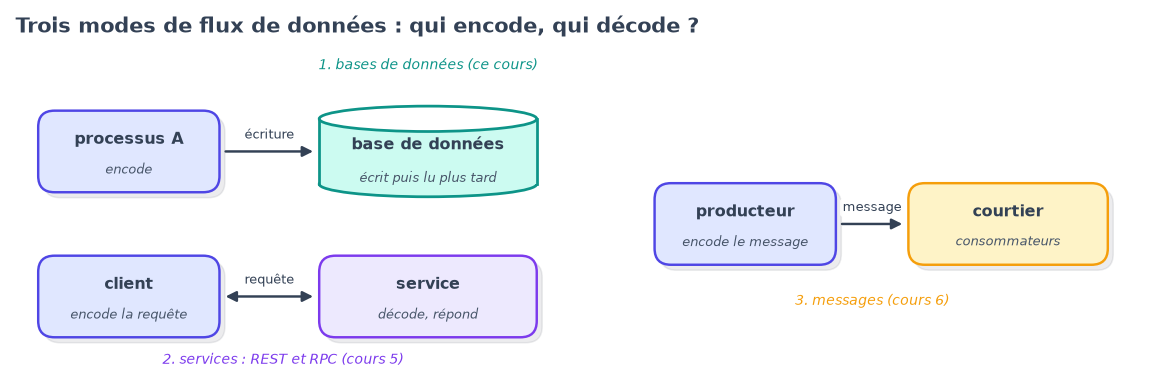

In [2]:
d = Diagram(12.5, 3.4, title="Trois modes de flux de données : qui encode, qui décode ?")
d.box("w", 1.3, 2.4, "processus A", sub="encode", color=INDIGO, w=2.0)
d.box("db", 4.6, 2.4, "base de données", sub="écrit puis lu plus tard", color=TEAL, kind="db", w=2.4, h=1.0)
d.box("c", 1.3, 0.8, "client", sub="encode la requête", color=INDIGO, w=2.0)
d.box("s", 4.6, 0.8, "service", sub="décode, répond", color=VIOLET, w=2.4)
d.box("p", 8.1, 1.6, "producteur", sub="encode le message", color=INDIGO, w=2.0)
d.box("b", 11.0, 1.6, "courtier", sub="consommateurs", color=AMBER, w=2.2)
d.arrow("w", "db", "écriture")
d.arrow("c", "s", "requête", both=True)
d.arrow("p", "b", "message")
d.note(4.6, 3.35, "1. bases de données (ce cours)", color=TEAL)
d.note(3.0, 0.1, "2. services : REST et RPC (cours 5)", color=VIOLET)
d.note(9.5, 0.75, "3. messages (cours 6)", color=AMBER)
d.show()

> **À retenir.** La compatibilité relie toujours un encodeur et un décodeur ; pour savoir
> laquelle il faut, on se demande qui écrit, qui lit, et avec quelles versions du code.